# 02 · Exploratory data analysis
All EDA uses the **training split only**; the test split is never looked at. Each chart is followed by an interpretation generated from the measured numbers.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().resolve()
while not (ROOT / "src" / "carprice").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
import json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display
from carprice.config import load_settings
S = load_settings()
P = S.paths
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30); pd.set_option("display.float_format", "{:,.3f}".format)
def show_fig(name):
    display(Image(filename=str(P.figures / name), width=900))
def md(text): display(Markdown(text))


In [2]:
md(open(P.reports / "eda_findings.md").read())

# EDA findings (training split only)

- **Price is strongly right-skewed** (skewness 2.81; mean ₹395,368 vs median ₹289,999). The middle car costs about ₹2.9 lakh while the top 1% exceed ₹18.9 lakh. After a log transform skewness drops to -0.04, so models are trained on log(price) and judged by relative error (RMSLE/MAPE) as well as rupees.

- **Brand drives price level**: Kruskal-Wallis across the 10 largest brands H = 108.3, p = 3.3e-19. Three brands account for 56% of listings, so the model is well informed about mass-market cars and thin on luxury brands (see per-segment errors).

- **Model coverage is sparse**: 128 model families, but 50% of them have at most 2 listings (median 2). A one-hot model column for a rare model cannot be learned reliably, which is why rare categories are pooled and why brand-level and engineered features matter.

- **Depreciation**: each additional year of age is associated with about 11.0% lower asking price (log-linear fit, R² = 0.33, 95% CI on the slope ±0.014). Age alone explains 33% of log-price variance; this is association, not a causal depreciation law, and the true curve is not perfectly linear.

- **Mileage is partly a proxy for age**: raw Spearman ρ(price, km) = -0.26, but after removing the age trend the residual correlation is only -0.05 (p = 0.23). Older cars have more km, so mileage adds less than its raw correlation suggests; odometer values under 1,000 km on cars >3 years old were treated as entry errors.

- **Diesel vs petrol**: median diesel ask ₹390,000 (95% CI 351,000–425,000) vs petrol ₹230,000 (210,000–250,000), a raw gap of +70% (Mann-Whitney p = 9.8e-16; a random diesel car out-prices a random petrol car 69% of the time). Median age is similar (5 vs 6 years), so age does not explain the gap. Holding model family and age fixed (regression with 65 model-family effects) the diesel premium is +8% - the difference between the two numbers is how much of the raw gap is simply that diesel buyers choose different (pricier) models. LPG has only 2 rows, so it cannot be modelled reliably.

- **What the data does not contain**: no transmission, owner-count, engine, power or location columns. Only 7% of listings state a gearbox in their text and 24% state an engine size. Those partial signals are used as clearly-named, nullable features (transmission_hint, engine_l) and NOT presented as complete transmission/engine data.

- **Multicollinearity**: highest VIF is 2.5 (kms_per_year). No serious multicollinearity among the numeric inputs (all VIF < 5). Age, odometer and km/year are related by construction, but not so tightly that OLS coefficients are unstable. The much larger instability risk is the high-cardinality, sparse one-hot brand/model columns, which is why regularised models and rare-category pooling are used.

- **Segments**: premium/luxury listings are only 28 of 581 rows (4.8%) but sell at 5.3x the median mass-market price. Their errors dominate RMSE; they are evaluated as a dedicated segment and are never removed as 'outliers'.

## Summary statistics (mean CI by bootstrap)

In [3]:
display(pd.read_csv(P.metrics / "eda_summary_stats.csv", index_col=0))

,n,mean,mean_ci95_low,mean_ci95_high,median,std,min,p1,p5,q1,q3,p95,p99,max,iqr,skewness,excess_kurtosis
index,,,,,,,,,,,,,,,,,
price_inr,581.000,"395,367.673","364,132.217","428,482.699","289,999.000","378,049.106","30,000.000","39,199.800","75,000.000","165,000.000","488,000.000","1,130,000.000","1,892,888.800","2,900,000.000","323,000.000",2.809,10.571
kms_driven,573.000,"46,465.534","44,071.845","48,915.564","42,000.000","29,412.702",0.000,"1,172.440","7,000.000","29,500.000","58,000.000","100,000.000","150,000.000","200,000.000","28,500.000",1.516,4.090
age,581.000,6.652,6.318,6.969,6.000,4.023,0.000,0.000,1.000,4.000,9.000,15.000,18.200,24.000,5.000,0.984,1.122
year,581.000,"2,012.348","2,012.031","2,012.682","2,013.000",4.023,"1,995.000","2,000.800","2,004.000","2,010.000","2,015.000","2,018.000","2,019.000","2,019.000",5.000,-0.984,1.122
kms_per_year,573.000,"9,268.944","8,441.035","10,186.126","6,500.000","10,075.698",0.000,406.154,"1,635.714","4,375.000","10,000.000","28,792.000","47,226.667","103,553.000","5,625.000",4.361,29.155


## Price distribution

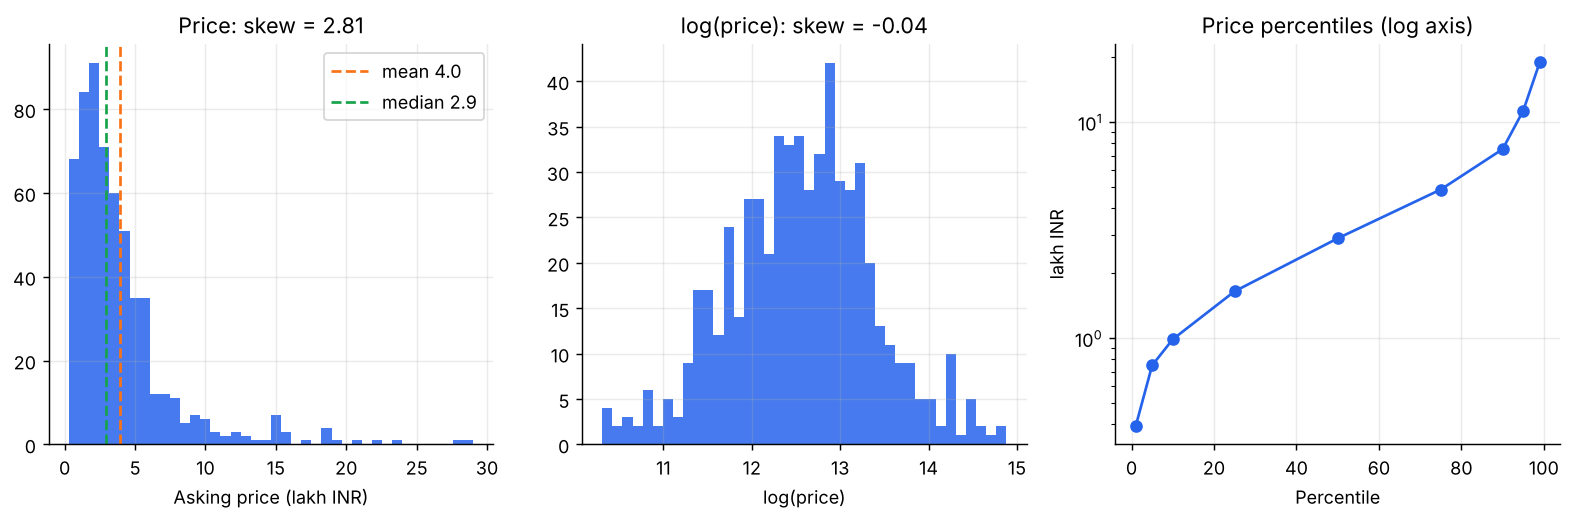

In [4]:
show_fig("eda_01_price_distribution.png")

Right-skewed prices → modelling on `log(price)`; errors judged in relative terms as well as rupees.

## Brand and model

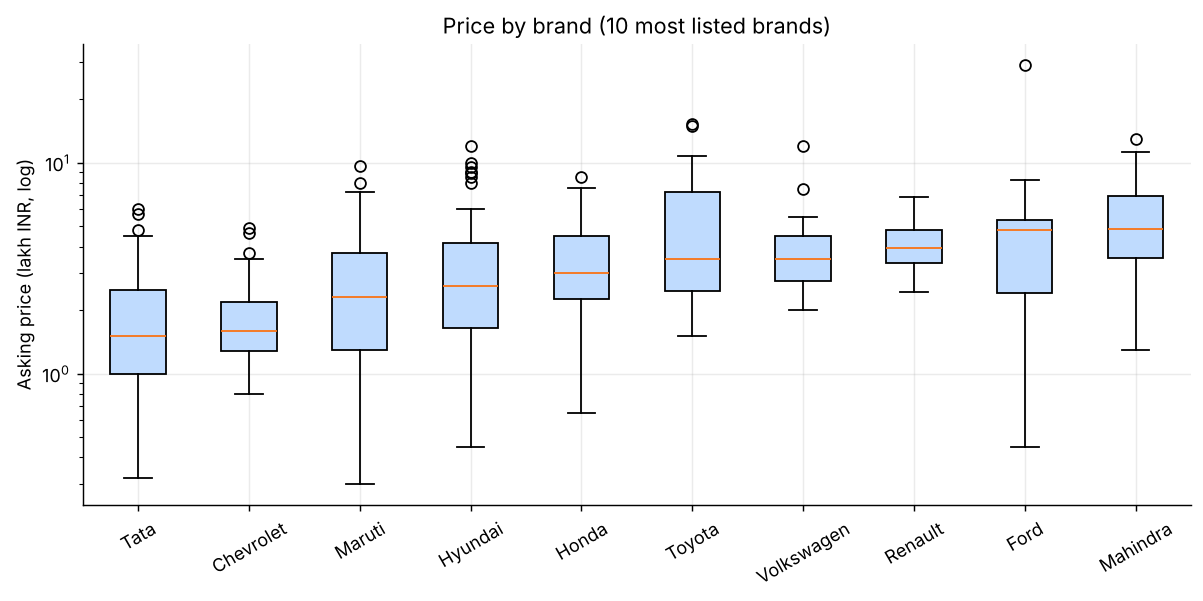

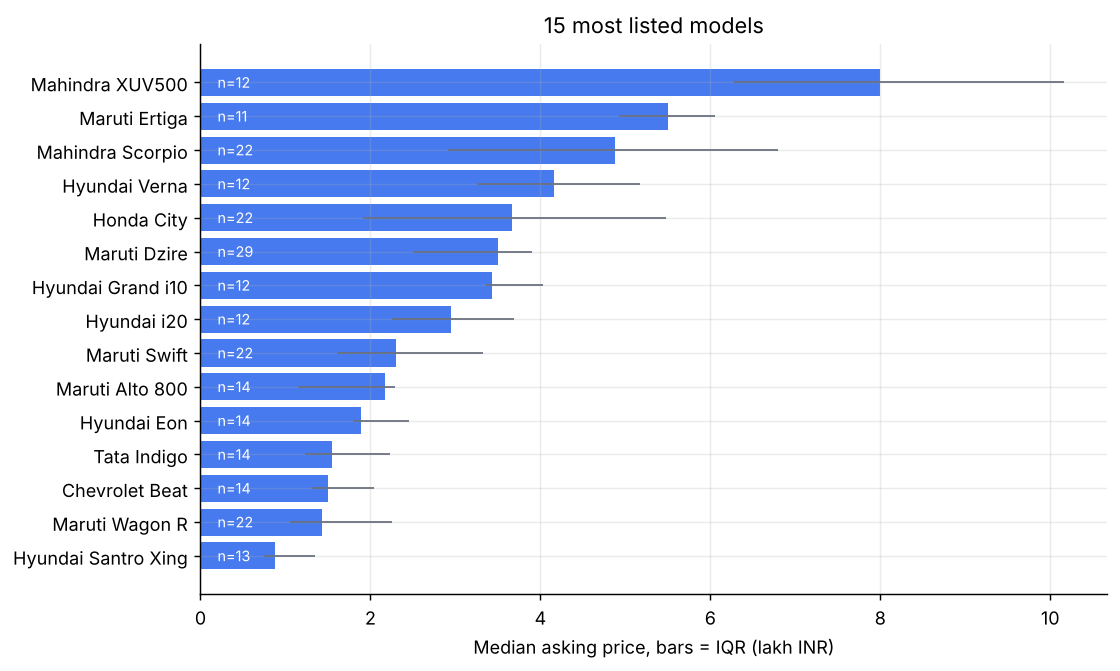

,company,n,median,mean,p10,p90
0,Maruti,160,"230,000.000","273,959.963","85,000.000","527,399.100"
1,Hyundai,105,"260,000.000","314,528.467","88,800.000","579,999.000"
2,Mahindra,60,"487,499.500","529,063.250","220,000.000","899,100.000"
3,Tata,49,"150,000.000","189,664.388","58,400.000","392,000.000"
4,Honda,41,"299,999.000","351,731.415","169,999.000","584,999.000"
5,Chevrolet,28,"159,200.000","197,174.964","99,550.000","357,500.000"
6,Toyota,26,"349,999.500","498,269.038","192,499.500","932,499.500"
7,Ford,20,"477,499.500","520,699.900","170,000.000","622,100.000"
8,Volkswagen,17,"350,000.000","421,176.176","224,000.000","629,999.600"
9,Renault,16,"392,499.500","410,936.938","280,000.000","519,999.500"


In [5]:
show_fig("eda_02_price_by_brand.png"); show_fig("eda_03_price_by_model.png")
display(pd.read_csv(P.metrics / "eda_price_by_brand.csv").head(12))

## Age, mileage and fuel

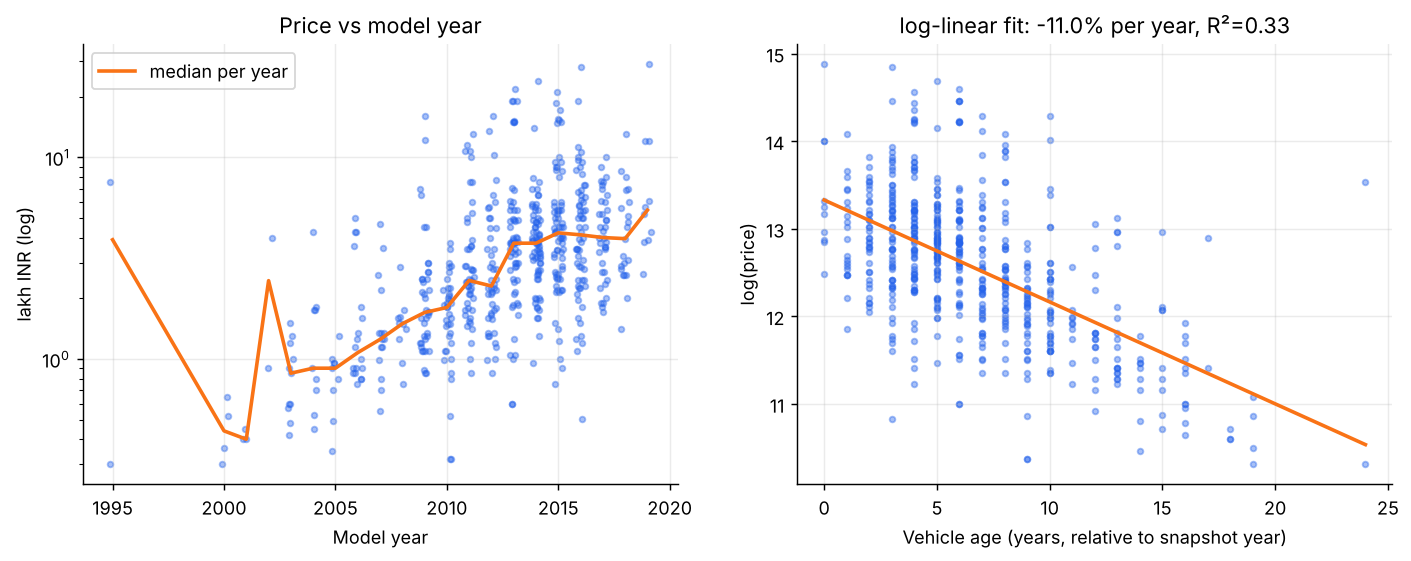

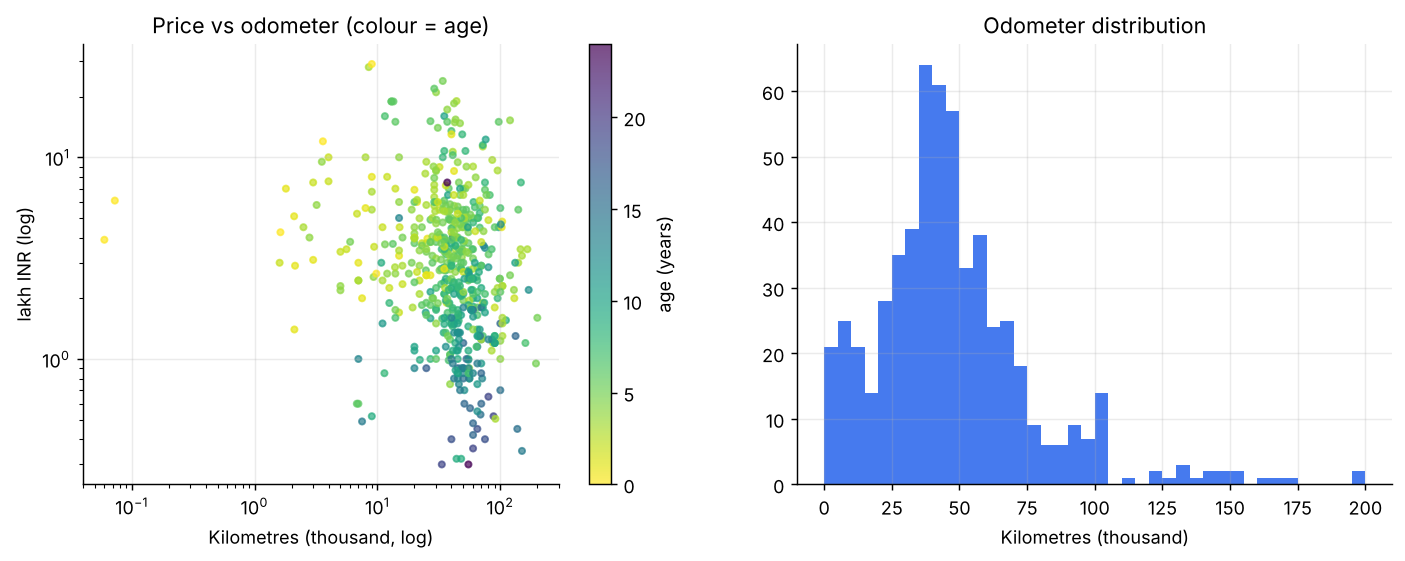

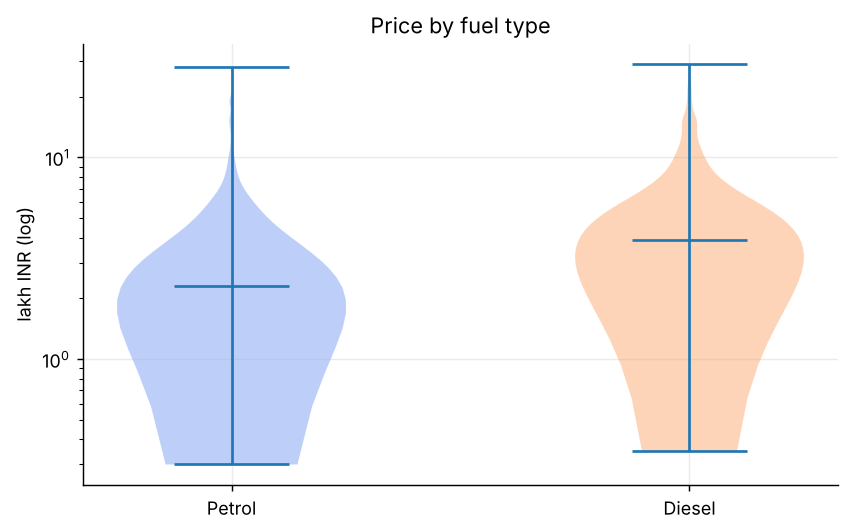

,index,fuel,n,median,ci95_low,ci95_high
0,0,Petrol,312,"230,000.000","210,000.000","250,000.000"
1,1,Diesel,267,"390,000.000","351,000.000","425,000.000"


In [6]:
show_fig("eda_04_price_vs_year.png"); show_fig("eda_05_price_vs_mileage.png"); show_fig("eda_06_price_by_fuel.png")
display(pd.read_csv(P.metrics / "eda_fuel_group_comparison.csv"))

## Composition, correlation, multicollinearity

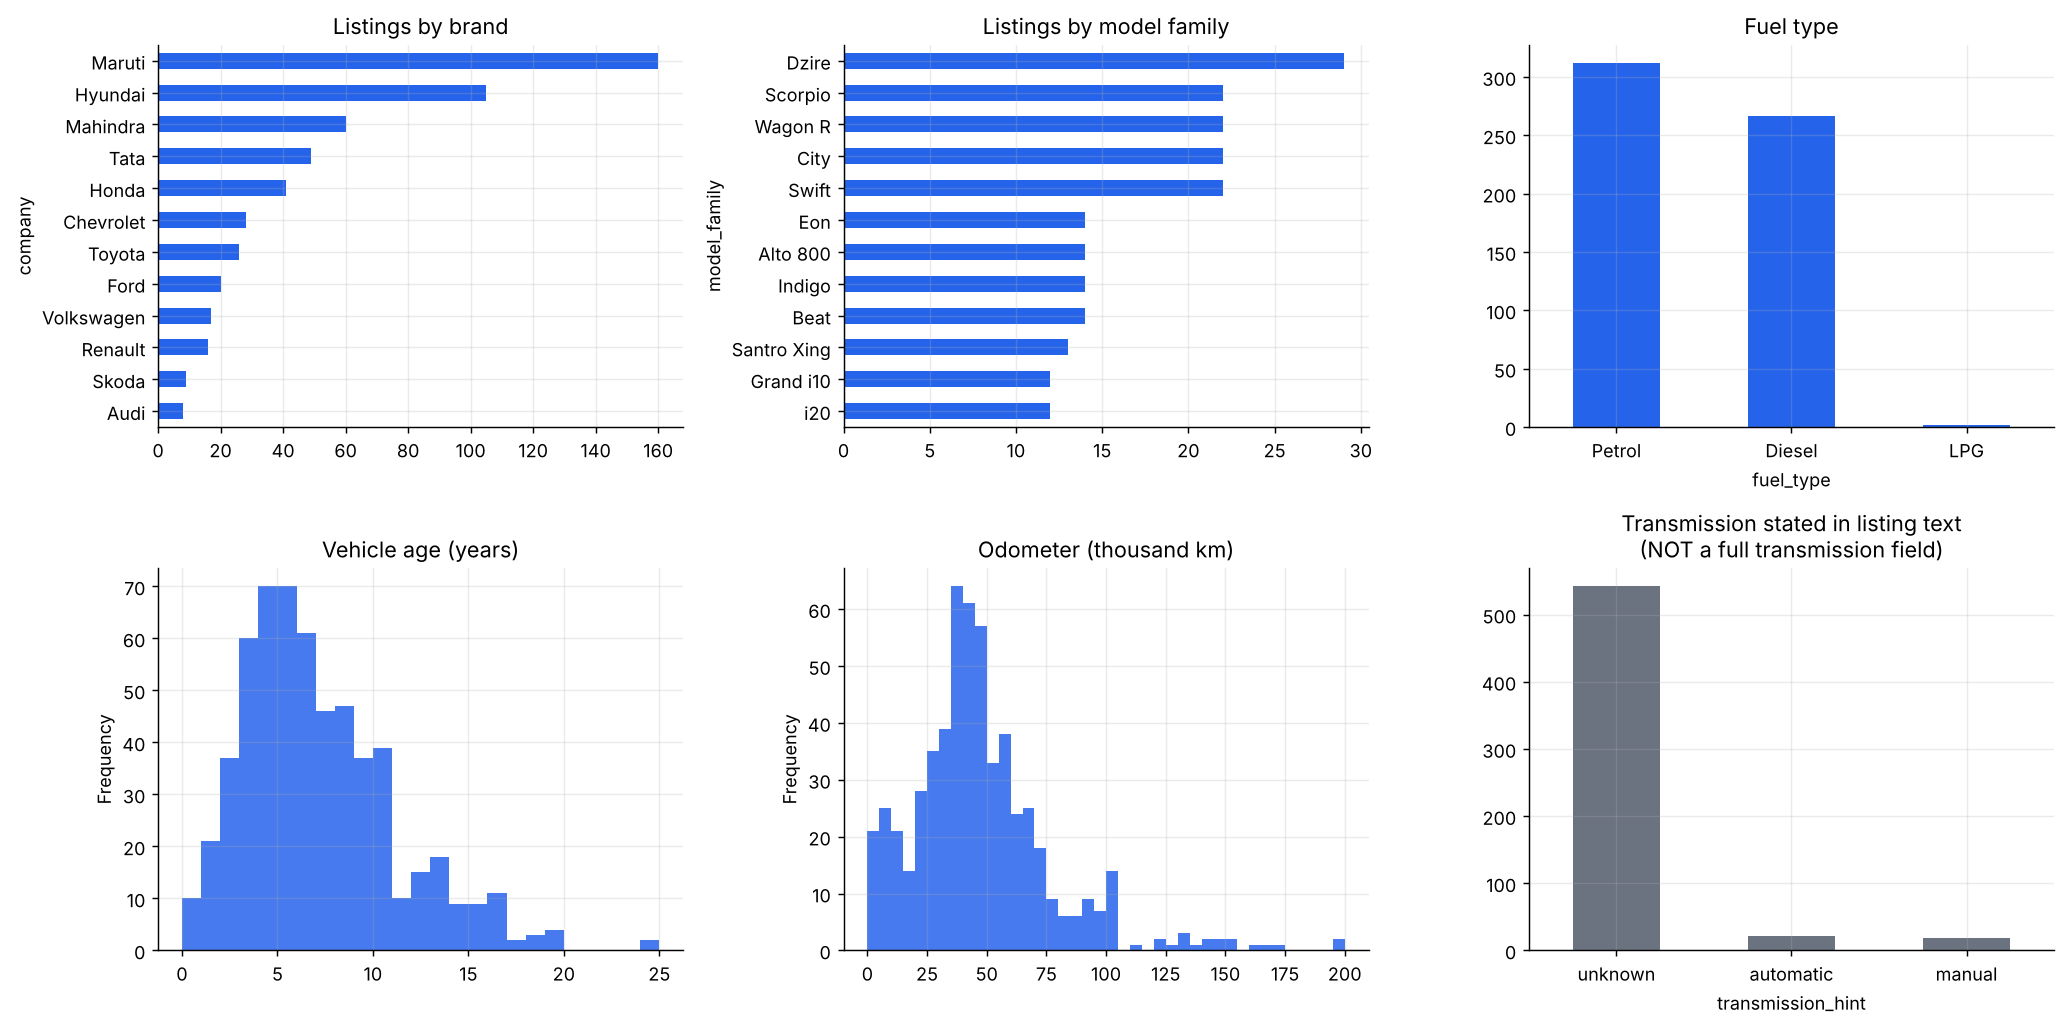

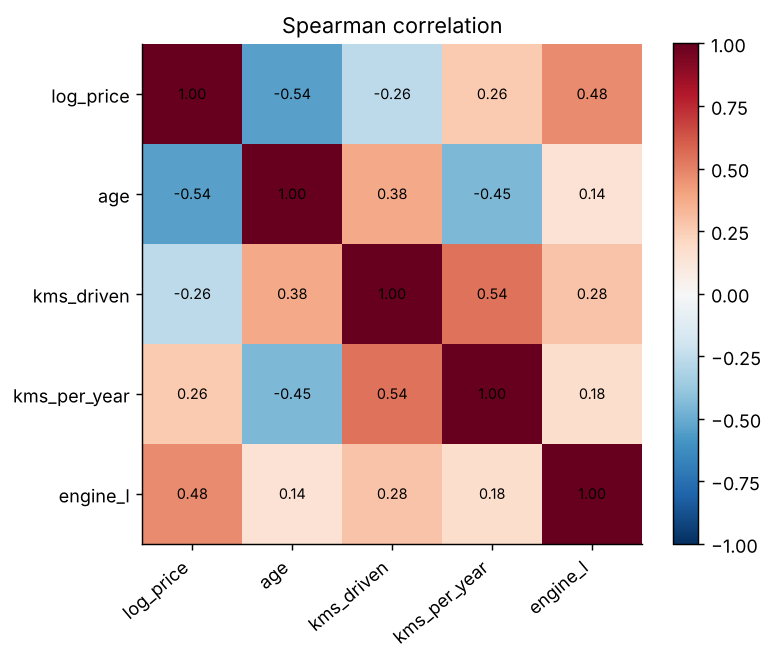

,index,feature,vif
0,0,age,1.853
1,1,kms_driven,2.360
2,2,kms_per_year,2.546


In [7]:
show_fig("eda_07_vehicle_composition.png"); show_fig("eda_08_correlation.png")
display(pd.read_csv(P.metrics / "eda_vif.csv"))

## Price ranges by vehicle category

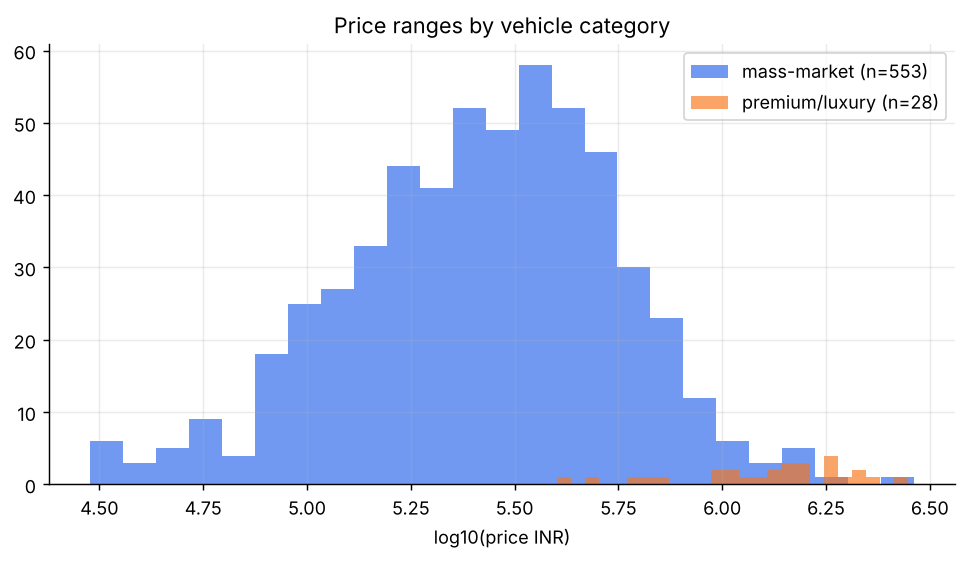

,tier,age_band,count,mean,std,min,10%,50%,90%,max
0,mass-market brands,0-2y,67.000,"511,365.552","387,258.742","140,000.000","215,000.000","425,000.000","799,999.400","2,900,000.000"
1,mass-market brands,3-5y,194.000,"449,765.851","282,415.311","50,500.000","179,999.300","390,000.000","819,500.000","1,725,000.000"
2,mass-market brands,6-8y,139.000,"318,048.065","200,015.685","60,000.000","129,000.000","275,000.000","552,000.000","1,499,000.000"
3,mass-market brands,9-12y,97.000,"176,696.371","87,987.355","32,000.000","85,000.000","159,000.000","286,999.600","465,000.000"
4,mass-market brands,13y+,56.000,"122,517.643","125,861.282","30,000.000","41,000.000","90,000.000","180,000.000","750,000.000"
5,premium/luxury brands,0-2y,1.000,"1,000,000.000",NaN,"1,000,000.000","1,000,000.000","1,000,000.000","1,000,000.000","1,000,000.000"
6,premium/luxury brands,3-5y,6.000,"2,073,333.333","482,147.972","1,400,000.000","1,625,000.000","2,000,000.000","2,595,000.000","2,800,000.000"
7,premium/luxury brands,6-8y,15.000,"1,431,355.533","424,758.377","600,000.000","1,010,000.000","1,499,000.000","1,891,111.000","2,190,000.000"
8,premium/luxury brands,9-12y,4.000,"1,043,500.000","453,194.954","650,000.000","664,700.000","962,000.000","1,487,500.000","1,600,000.000"
9,premium/luxury brands,13y+,2.000,"449,500.500","71,418.492","399,000.000","409,100.100","449,500.500","489,900.900","500,001.000"


In [8]:
show_fig("eda_09_price_by_category.png")
display(pd.read_csv(P.metrics / "eda_price_range_by_tier_age.csv"))